# Predicting Retail Food Prices in Rwandan Markets

**Mission:** digitalizing Africa's physical sectors.

**Use case:** predict the retail price (RWF per KG) of a food commodity in a given Rwandan market and month.
**Who uses it:** farmer cooperatives and agri-traders deciding *where* (which market) and *when* (which month)
to sell their produce to get the best price.

**Dataset:** [WFP Food Prices for Rwanda](https://data.humdata.org/dataset/wfp-food-prices-for-rwanda) (World Food
Programme via HDX, CC-BY-IGO). 157,793 rows, 16 columns, 2000–2026, 109 markets, 65 commodities. Mix of numeric
(latitude, longitude, price) and categorical (province, district, market, category, commodity, unit...) columns.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import SGDRegressor, LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")

## 1. Load and inspect

In [2]:
df = pd.read_csv("wfp_food_prices_rwa.csv")
print(df.shape)
df.head()

(157793, 16)


,date,admin1,admin2,market,market_id,latitude,longitude,category,commodity,commodity_id,unit,priceflag,pricetype,currency,price,usdprice
0,2000-01-15,Kigali City,Nyarugenge,Kigali,1076,-1.95,30.06,cereals and tubers,Maize,51,KG,actual,Wholesale,RWF,206.11,0.60
1,2000-01-15,Kigali City,Nyarugenge,Kigali,1076,-1.95,30.06,pulses and nuts,Beans,50,KG,actual,Wholesale,RWF,108.02,0.32
2,2000-02-15,Kigali City,Nyarugenge,Kigali,1076,-1.95,30.06,cereals and tubers,Maize,51,KG,actual,Wholesale,RWF,152.66,0.45
3,2000-02-15,Kigali City,Nyarugenge,Kigali,1076,-1.95,30.06,pulses and nuts,Beans,50,KG,actual,Wholesale,RWF,110.22,0.32
4,2000-03-15,Kigali City,Nyarugenge,Kigali,1076,-1.95,30.06,cereals and tubers,Maize,51,KG,actual,Wholesale,RWF,159.27,0.47


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 157793 entries, 0 to 157792
Data columns (total 16 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   date          157793 non-null  object 
 1   admin1        157793 non-null  object 
 2   admin2        157793 non-null  object 
 3   market        157793 non-null  object 
 4   market_id     157793 non-null  int64  
 5   latitude      157793 non-null  float64
 6   longitude     157793 non-null  float64
 7   category      157793 non-null  object 
 8   commodity     157793 non-null  object 
 9   commodity_id  157793 non-null  int64  
 10  unit          157793 non-null  object 
 11  priceflag     157793 non-null  object 
 12  pricetype     157793 non-null  object 
 13  currency      157793 non-null  object 
 14  price         157793 non-null  float64
 15  usdprice      157793 non-null  float64
dtypes: float64(4), int64(2), object(10)
memory usage: 19.3+ MB


In [4]:
for col in ["unit", "pricetype", "currency", "priceflag", "category"]:
    print(df[col].value_counts(), "\n")

unit
KG      138579
Unit     10485
L         5930
Sack      2799
Name: count, dtype: int64 

pricetype
Retail       157124
Wholesale       669
Name: count, dtype: int64 

currency
RWF    157793
Name: count, dtype: int64 

priceflag
actual              148105
actual,aggregate      6520
aggregate             3168
Name: count, dtype: int64 

category
cereals and tubers       64550
vegetables and fruits    51832
meat, fish and eggs      15837
pulses and nuts          12327
miscellaneous food        4518
oil and fats              4027
non-food                  2799
milk and dairy            1903
Name: count, dtype: int64 



## 2. Clean

* **unit** is KG, L, Sack or "Unit" (a bunch, a head, a piece...). Prices per litre, per sack and per piece are not
  comparable with prices per KG, so I keep **KG only** (~88% of rows). The target becomes *RWF per KG*.
* **pricetype**: 99.5% of rows are Retail. Cooperatives sell into retail markets, so I keep **Retail only**.
* **date** is a string: split it into **year** (captures inflation) and **month** (captures harvest seasonality).

In [5]:
data = df[(df["unit"] == "KG") & (df["pricetype"] == "Retail")].copy()

data["date"] = pd.to_datetime(data["date"])
data["year"] = data["date"].dt.year
data["month"] = data["date"].dt.month

print("rows after filtering:", len(data))
print("missing values:", data.isna().sum().sum(), "| duplicate rows:", data.duplicated().sum())

rows after filtering: 137910


missing values: 0 | duplicate rows: 0


## 3. Explore

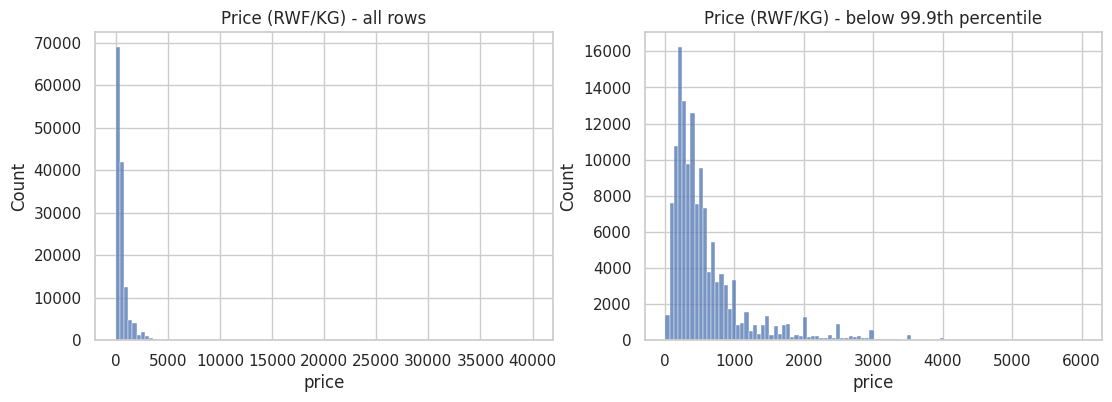

count    137910.000000
mean        609.692999
std         632.834108
min          11.000000
50%         410.000000
99%        3000.000000
99.9%      6000.000000
max       39956.000000
Name: price, dtype: float64


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(data["price"], bins=100, ax=axes[0])
axes[0].set_title("Price (RWF/KG) - all rows")
sns.histplot(data.loc[data["price"] <= data["price"].quantile(0.999), "price"], bins=100, ax=axes[1])
axes[1].set_title("Price (RWF/KG) - below 99.9th percentile")
plt.show()

print(data["price"].describe(percentiles=[0.5, 0.99, 0.999]))

**What it shows:** the price is strongly right-skewed: the median is about 400 RWF/KG, 99.9% of rows are under
6,000 RWF/KG, but a handful go up to ~40,000 RWF/KG (likely data-entry errors, e.g. a per-sack price recorded per KG).

**Decision:** drop rows above the 99.9th percentile. A squared-error loss (MSE) punishes those few points so much
that they would dominate the fit, especially for the linear models.

In [7]:
cap = data["price"].quantile(0.999)
data = data[data["price"] <= cap]
print(f"cap = {cap:.0f} RWF/KG, rows kept = {len(data)}")

cap = 6000 RWF/KG, rows kept = 137790


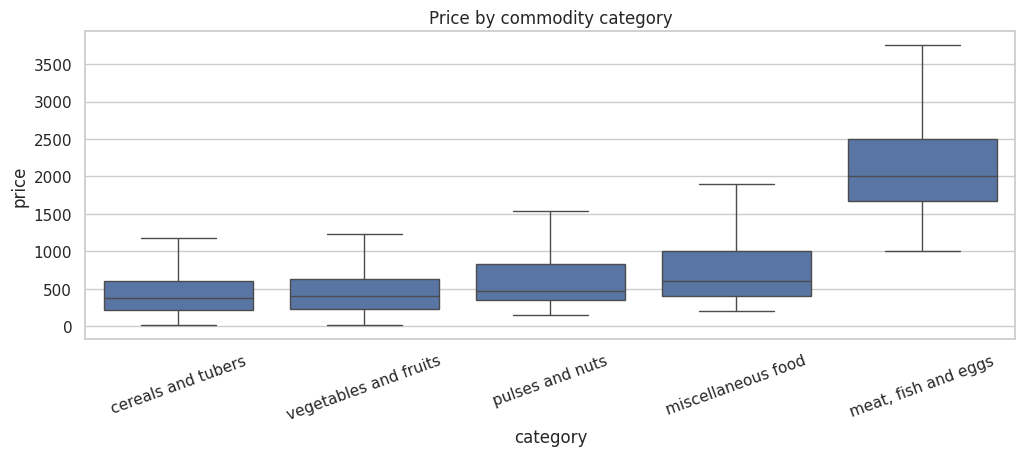

In [8]:
order = data.groupby("category")["price"].median().sort_values().index
plt.figure(figsize=(12, 4))
sns.boxplot(data=data, x="category", y="price", order=order, showfliers=False)
plt.title("Price by commodity category")
plt.xticks(rotation=20)
plt.show()

**What it shows:** price depends heavily on *what* is sold: meat, fish and eggs, and oils, sit several times above
cereals, tubers and vegetables.

**Decision:** `category` and `commodity` are the most important inputs and must be kept, converted to numbers with
one-hot encoding (they have no natural order, so label numbers 0, 1, 2... would invent a fake ranking).

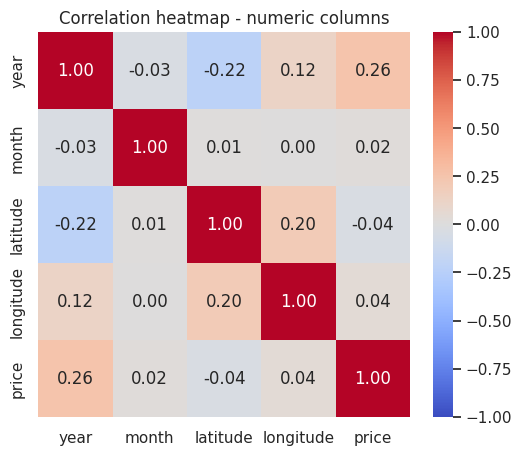

In [9]:
numeric = data[["year", "month", "latitude", "longitude", "price"]]
plt.figure(figsize=(6, 5))
sns.heatmap(numeric.corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation heatmap - numeric columns")
plt.show()

**What it shows:** among numeric columns, `year` has the strongest correlation with price (~0.27, inflation over
time). `month`, `latitude` and `longitude` are almost uncorrelated with price on their own.

**Decision:** keep `year` (it is the feature used for the one-feature scatter plots later). Keep month and location
too: their effect is not linear on its own (seasonality, location × commodity interactions), which tree models can
exploit even though the correlation is near zero. The weak linear signal also tells me the linear models will
struggle compared with the tree models.

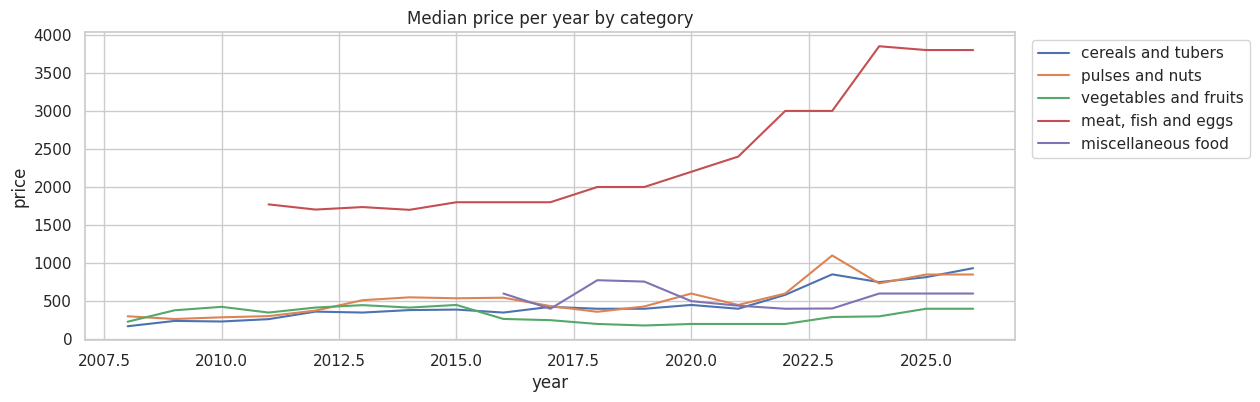

In [10]:
plt.figure(figsize=(12, 4))
yearly = data.groupby(["year", "category"])["price"].median().reset_index()
sns.lineplot(data=yearly[yearly["year"] >= 2008], x="year", y="price", hue="category")
plt.title("Median price per year by category")
plt.legend(bbox_to_anchor=(1.01, 1), loc="upper left")
plt.show()

**What it shows:** prices rise over time, but at different speeds per category (meat rises much faster than
cereals). The effect of `year` depends on the commodity.

**Decision:** this interaction cannot be expressed by a single straight line, which is another reason to expect the
decision tree and random forest to beat linear regression.

## 4. Feature engineering

| Dropped column | Why |
|---|---|
| `usdprice` | It is `price` divided by the exchange rate - using it would leak the answer (target leakage). |
| `date` | Replaced by `year` and `month`. |
| `unit`, `pricetype`, `currency` | Constant after filtering (KG, Retail, RWF) - no information. |
| `market_id`, `commodity_id` | Duplicate IDs of `market` and `commodity`. |
| `priceflag` | Describes how WFP aggregated the record, not something a trader knows when asking for a price. |

**Features kept (9):** `commodity`, `category`, `market`, `admin2` (district), `admin1` (province), `latitude`,
`longitude`, `year`, `month`.  **Target:** `price` (RWF/KG).

Most important for the target: `commodity`/`category` (what is sold, see box plot), then `year` (inflation, strongest
numeric correlation), then location and month.

In [11]:
CATEGORICAL = ["commodity", "category", "market", "admin2", "admin1"]
NUMERIC = ["latitude", "longitude", "year", "month"]
FEATURES = CATEGORICAL + NUMERIC
TARGET = "price"

X = data[FEATURES]
y = data[TARGET]
print(X.shape)
X.head()

(137790, 9)


,commodity,category,market,admin2,admin1,latitude,longitude,year,month
162,Cassava,cereals and tubers,Ruhuha,Bugesera,Eastern Province,-2.15,30.09,2008,1
163,Cassava flour,cereals and tubers,Ruhuha,Bugesera,Eastern Province,-2.15,30.09,2008,1
164,Maize,cereals and tubers,Ruhuha,Bugesera,Eastern Province,-2.15,30.09,2008,1
165,Maize flour,cereals and tubers,Ruhuha,Bugesera,Eastern Province,-2.15,30.09,2008,1
166,Potatoes (Irish),cereals and tubers,Ruhuha,Bugesera,Eastern Province,-2.15,30.09,2008,1


## 5. Split and standardize

80/20 train/test split. Categorical columns are converted to numbers in two ways, each suited to a model family:

* **Linear models** -> `OneHotEncoder`: one 0/1 column per category. A linear model multiplies every input by a
  weight, so label numbers (Maize = 1, Beef = 2...) would invent a fake order; one-hot avoids that (204 columns).
* **Tree models** -> `OrdinalEncoder`: one integer per category (9 columns). Trees only ask "is the code ≤ k?", and
  across many splits they can isolate any category, so no fake-order problem. 9 columns instead of 204 makes the
  random forest ~10× faster to train and small enough to deploy and retrain on Render's free tier, with the same
  accuracy (tested).
* Numeric columns -> `StandardScaler` in both (mean 0, std 1, so gradient descent takes balanced steps).

Both transformers are **fit on the training set only**, then applied to the test set, so no test information leaks
into training. Unknown categories at prediction time are handled instead of crashing.

In [12]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)

preprocessor = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), CATEGORICAL),
    ("num", StandardScaler(), NUMERIC),
])
X_train_p = preprocessor.fit_transform(X_train)   # fit on train only
X_test_p = preprocessor.transform(X_test)

tree_preprocessor = ColumnTransformer([
    ("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), CATEGORICAL),
    ("num", StandardScaler(), NUMERIC),
])
X_train_t = tree_preprocessor.fit_transform(X_train)   # fit on train only
X_test_t = tree_preprocessor.transform(X_test)

print("linear models - train:", X_train_p.shape, "| test:", X_test_p.shape)
print("tree models   - train:", X_train_t.shape, "| test:", X_test_t.shape)

linear models - train: (110232, 204) | test: (27558, 204)
tree models   - train: (110232, 9) | test: (27558, 9)


## 6. Model 1 - Linear regression by gradient descent (`SGDRegressor`)

scikit-learn does not record the loss per epoch, so I train with `partial_fit` (one pass over the shuffled training
data per call) and compute train and test MSE after every epoch.

**Tuning:** to avoid tuning on the test set, I carve a validation set out of the training data and try different
learning rates (`eta0`), regularization strengths (`alpha`, L2 penalty) and numbers of epochs.

In [13]:
def train_sgd(X_fit, y_fit, X_eval, y_eval, eta0, alpha, epochs, seed=RANDOM_STATE):
    """Train SGDRegressor epoch by epoch; return the model and per-epoch MSE histories."""
    model = SGDRegressor(learning_rate="constant", eta0=eta0, alpha=alpha, penalty="l2", random_state=seed)
    rng = np.random.default_rng(seed)
    y_fit = np.asarray(y_fit)
    fit_hist, eval_hist = [], []
    for _ in range(epochs):
        idx = rng.permutation(X_fit.shape[0])          # shuffle every epoch
        model.partial_fit(X_fit[idx], y_fit[idx])
        fit_hist.append(mean_squared_error(y_fit, model.predict(X_fit)))
        eval_hist.append(mean_squared_error(y_eval, model.predict(X_eval)))
    return model, fit_hist, eval_hist


# validation split carved out of the training set (test set stays untouched)
X_tr, X_val, y_tr, y_val = train_test_split(X_train, y_train, test_size=0.2, random_state=RANDOM_STATE)
tune_pre = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), CATEGORICAL),
    ("num", StandardScaler(), NUMERIC),
])
X_tr_p = tune_pre.fit_transform(X_tr)
X_val_p = tune_pre.transform(X_val)

results = []
for eta0 in [0.0001, 0.001, 0.01]:
    for alpha in [0.0001, 0.001, 0.01]:
        _, tr_hist, val_hist = train_sgd(X_tr_p, y_tr, X_val_p, y_val, eta0, alpha, epochs=50)
        for epochs in [10, 25, 50]:
            results.append({"eta0": eta0, "alpha": alpha, "epochs": epochs,
                            "train_mse": tr_hist[epochs - 1], "val_mse": val_hist[epochs - 1]})

tuning = pd.DataFrame(results).sort_values("val_mse")
tuning.head(10)

,eta0,alpha,epochs,train_mse,val_mse
9,0.0010,0.0001,10,49708.689167,50264.607331
11,0.0010,0.0001,50,49736.892388,50284.505387
10,0.0010,0.0001,25,49680.664190,50287.238317
2,0.0001,0.0001,50,49975.549518,50561.880711
13,0.0010,0.0010,25,50654.792485,51173.015356
20,0.0100,0.0001,50,50761.616274,51213.428001
12,0.0010,0.0010,10,50766.513097,51229.363340
14,0.0010,0.0010,50,50773.478430,51229.982383
5,0.0001,0.0010,50,51137.913724,51656.670473
23,0.0100,0.0010,50,51647.430852,51993.030549


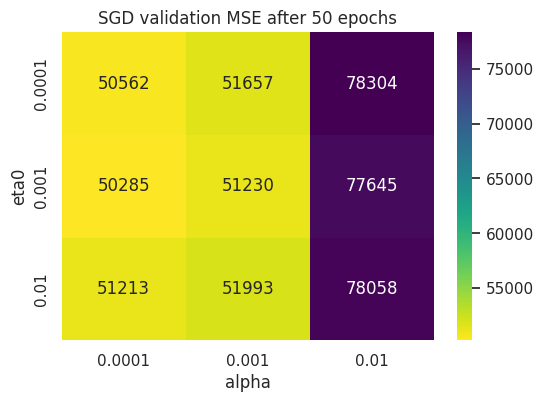

best: eta0=0.001, alpha=0.0001, epochs=10, val MSE=50265


In [14]:
pivot = tuning[tuning["epochs"] == 50].pivot(index="eta0", columns="alpha", values="val_mse")
plt.figure(figsize=(6, 4))
sns.heatmap(pivot, annot=True, fmt=".0f", cmap="viridis_r")
plt.title("SGD validation MSE after 50 epochs")
plt.show()

best = tuning.iloc[0]
BEST_ETA0, BEST_ALPHA, BEST_EPOCHS = best["eta0"], best["alpha"], int(best["epochs"])
print(f"best: eta0={BEST_ETA0}, alpha={BEST_ALPHA}, epochs={BEST_EPOCHS}, val MSE={best['val_mse']:.0f}")

**Tuning observations** (validation MSE, table and heatmap above):
* **Learning rate (`eta0`)** has the biggest effect. `0.001` is best. `0.0001` takes small steps, so it needs many
  more epochs to get close to the minimum. `0.01` takes steps that are too big: the weights overshoot around the
  minimum and the loss stays higher.
* **Regularization (`alpha`, L2)**: raising it from `0.0001` to `0.01` steadily *increases* the loss. The linear model
  is underfitting (train and validation MSE are almost equal), so shrinking its weights further only hurts.
* **Epochs**: with `eta0=0.001` the loss has already converged after ~10 epochs; 25 or 50 epochs give no improvement,
  so 10 epochs is kept (less computation for the same loss).

### Loss curve (train vs test MSE per epoch) with the tuned hyperparameters

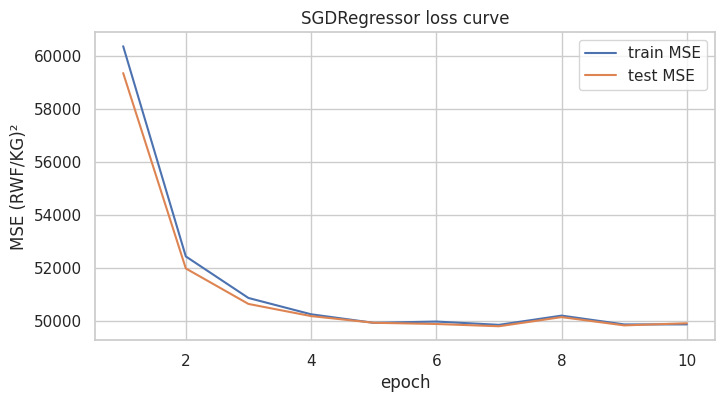

In [15]:
sgd, sgd_train_hist, sgd_test_hist = train_sgd(X_train_p, y_train, X_test_p, y_test,
                                               BEST_ETA0, BEST_ALPHA, BEST_EPOCHS)

plt.figure(figsize=(8, 4))
epochs_axis = range(1, BEST_EPOCHS + 1)
plt.plot(epochs_axis, sgd_train_hist, label="train MSE")
plt.plot(epochs_axis, sgd_test_hist, label="test MSE")
plt.xlabel("epoch")
plt.ylabel("MSE (RWF/KG)²")
plt.title("SGDRegressor loss curve")
plt.legend()
plt.show()

The two curves drop quickly in the first epochs and then flatten, and they stay close to each other: the model is
not overfitting, it is **underfitting** - a straight-line model cannot capture the commodity × time interactions.

## 7. Models 2-4: closed-form linear regression, decision tree, random forest

In [16]:
# name -> (model, its preprocessor, encoded train set, encoded test set)
models = {
    "SGDRegressor (gradient descent)": (sgd, preprocessor, X_train_p, X_test_p),
    "LinearRegression (closed form)": (LinearRegression(), preprocessor, X_train_p, X_test_p),
    "DecisionTreeRegressor": (DecisionTreeRegressor(min_samples_leaf=5, random_state=RANDOM_STATE),
                              tree_preprocessor, X_train_t, X_test_t),
    "RandomForestRegressor": (RandomForestRegressor(n_estimators=50, min_samples_leaf=5, n_jobs=-1,
                                                    random_state=RANDOM_STATE),
                              tree_preprocessor, X_train_t, X_test_t),
}

rows = []
for name, (model, _, Xtr_enc, Xte_enc) in models.items():
    if name != "SGDRegressor (gradient descent)":    # SGD is already trained above
        model.fit(Xtr_enc, y_train)
    rows.append({
        "model": name,
        "train_mse": mean_squared_error(y_train, model.predict(Xtr_enc)),
        "test_mse": mean_squared_error(y_test, model.predict(Xte_enc)),
    })

comparison = pd.DataFrame(rows).sort_values("test_mse").reset_index(drop=True)
comparison["test_rmse (RWF/KG)"] = np.sqrt(comparison["test_mse"])
comparison.style.format({"train_mse": "{:,.0f}", "test_mse": "{:,.0f}", "test_rmse (RWF/KG)": "{:,.0f}"})

,model,train_mse,test_mse,test_rmse (RWF/KG)
0,RandomForestRegressor,"7,074","10,687",103
1,DecisionTreeRegressor,"6,892","13,123",115
2,LinearRegression (closed form),"49,667","49,680",223
3,SGDRegressor (gradient descent),"49,867","49,910",223


In [17]:
best_name = comparison.loc[0, "model"]
print(f"Best model (lowest test MSE): {best_name}")
print(f"Test MSE = {comparison.loc[0, 'test_mse']:,.0f}  ->  typical error ≈ {comparison.loc[0, 'test_rmse (RWF/KG)']:,.0f} RWF/KG"
      f"  (mean price ≈ {y_test.mean():,.0f} RWF/KG)")

Best model (lowest test MSE): RandomForestRegressor
Test MSE = 10,687  ->  typical error ≈ 103 RWF/KG  (mean price ≈ 600 RWF/KG)


### Best model: the one with the lowest **test MSE** — the Random Forest

**Criterion:** all four models are evaluated on the same held-out test set with MSE; the lowest test MSE wins.

**How the dataset shaped each model's performance:**
* **SGDRegressor and LinearRegression** reach almost the same, highest MSE: both fit one straight line (one weight
  per feature). The price of a KG of beef rises much faster over the years than the price of a KG of maize, and a
  linear model cannot express that interaction. Gradient descent converges towards the same solution as the closed
  form, which confirms the SGD is correctly tuned.
* **DecisionTreeRegressor** can split on commodity, then year, then market, so it captures interactions and its error
  drops a lot - but a single tree memorises noise (train MSE much lower than test MSE).
* **RandomForestRegressor** averages 50 trees, each trained on a bootstrap sample of the rows, which keeps the
  interactions while cancelling out much of the single-tree noise. It has the lowest test MSE, so it is the saved
  model. (50 trees with at least 5 rows per leaf: 100 trees lowered the test MSE by only ~7% but doubled the file
  size and training time, which matters for deploying and retraining on Render's free tier.)

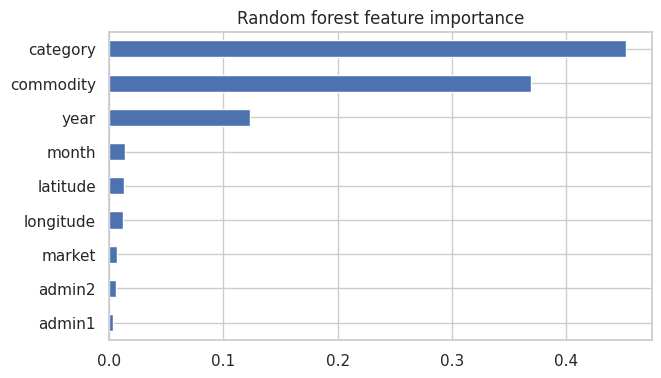

In [18]:
forest = models["RandomForestRegressor"][0]
importance = pd.Series(forest.feature_importances_, index=FEATURES).sort_values()
importance.plot.barh(figsize=(7, 4), title="Random forest feature importance")
plt.show()

The forest confirms the exploration: **commodity** is by far the most important feature, followed by **year**
(inflation); location and month add smaller refinements.

## 8. Scatter plots: most correlated feature vs target

`year` is the numeric feature most correlated with price (heatmap above). For this plot only, I fit a one-feature
linear regression `price ~ year`.

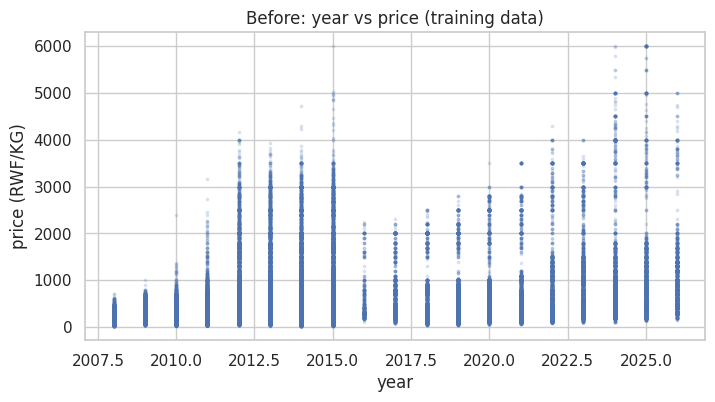

In [19]:
plt.figure(figsize=(8, 4))
plt.scatter(X_train["year"], y_train, s=3, alpha=0.15)
plt.xlabel("year")
plt.ylabel("price (RWF/KG)")
plt.title("Before: year vs price (training data)")
plt.show()

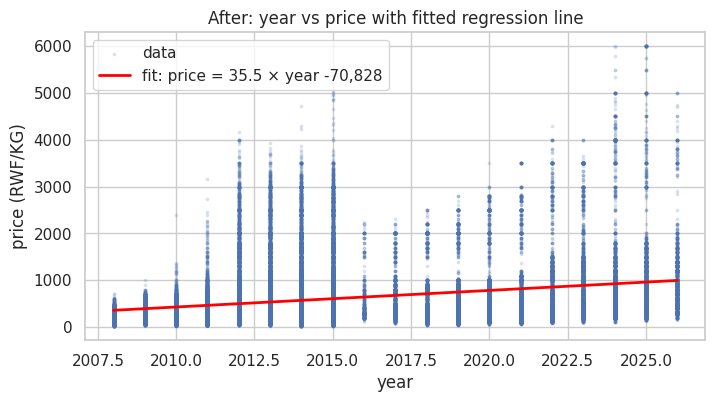

In [20]:
line_model = LinearRegression().fit(X_train[["year"]], y_train)
years = np.arange(X_train["year"].min(), X_train["year"].max() + 1).reshape(-1, 1)

plt.figure(figsize=(8, 4))
plt.scatter(X_train["year"], y_train, s=3, alpha=0.15, label="data")
plt.plot(years, line_model.predict(pd.DataFrame(years, columns=["year"])), color="red", linewidth=2,
         label=f"fit: price = {line_model.coef_[0]:.1f} × year {line_model.intercept_:+,.0f}")
plt.xlabel("year")
plt.ylabel("price (RWF/KG)")
plt.title("After: year vs price with fitted regression line")
plt.legend(loc="upper left")
plt.show()

The line slopes upward (prices rise by roughly the coefficient above every year), but the vertical spread around it
is huge: year alone explains little of the price, which is why the full model needs the commodity and the market.

## 9. Save the best model with its preprocessing

The saved object is a scikit-learn `Pipeline` = the best model's preprocessing (encoder + scaler) + the best model,
both already fitted on the training set. Loading it gives a single object that takes the 9 raw columns and returns a
price. It is saved into the API folder, together with the cleaned data the API needs for retraining.

In [21]:
# both parts are already fitted on the training set only: the preprocessor in section 5, the model in section 7
best_model, best_preprocessor, _, _ = models[best_name]
best_pipeline = Pipeline([
    ("preprocess", best_preprocessor),
    ("model", best_model),
])

print("pipeline test MSE:", f"{mean_squared_error(y_test, best_pipeline.predict(X_test)):,.0f}")

joblib.dump(best_pipeline, "../API/best_model.pkl", compress=3)
data[FEATURES + [TARGET]].to_csv("../API/training_data.csv.gz", index=False)
print("saved ../API/best_model.pkl and ../API/training_data.csv.gz")

pipeline test MSE: 10,687


saved ../API/best_model.pkl and ../API/training_data.csv.gz


## 10. Predict one row of the test set (reused by the API)

In [22]:
def predict_price(row: pd.DataFrame, model_path: str = "../API/best_model.pkl") -> float:
    """Load the saved pipeline and predict the price (RWF/KG) for one row of raw features."""
    model = joblib.load(model_path)
    return float(model.predict(row[FEATURES])[0])


one_row = X_test.iloc[[0]]
display(one_row)
print(f"predicted: {predict_price(one_row):,.0f} RWF/KG | actual: {y_test.iloc[0]:,.0f} RWF/KG")

,commodity,category,market,admin2,admin1,latitude,longitude,year,month
6842,"Rice (imported, Tanzanian)",cereals and tubers,Mukamira,Nyabihu,Western Province,-1.61,29.51,2009,8


predicted: 641 RWF/KG | actual: 700 RWF/KG
